# Heart Rate Estimation from Optical Sensor Data and Finger Video

**MPHY0058 – Introduction to Programming in Biomedical Engineering**
**Group Coursework: Signal and Image Processing**
**Group 20**

| Name | GitHub username |
|---|---|
| Minnan Tan | (your username) |
| Eric Xia | Xc1Re |
| Simon Sun | (username) |
| (name) | (username) |
| (name) | (username) |

**GitHub repository:** https://github.com/Xc1Re/G20
**Python environment:** `MPHY0058_environment` (Python 3.14)

**Contents**
- Part A: Optical Sensor (Problem 1) – Tasks 1.1 and 1.2
- Part B: Video Recording from the Camera (Problem 2) – Tasks 2.1 and 2.2

## Part A Optical sensor
### Problem 1.1 - Optical sensor signal

In [ ]:
# Import the libraries used in this section
import os           # to create a folder for saving figures
import numpy as np  # numerical arrays and maths
import matplotlib.pyplot as plt  # plotting 

# 1.Read the comma-separated data 
# 
data = np.genfromtxt("data/heart_beat_signal.csv", delimiter=",")

## Part B: Video Heart Rate Analysis

### Problem 2.1

In [ ]:
# Import libraries
import os
import numpy as np
import matplotlib.pyplot as plt

# Define the relative path to the input video
video_path = os.path.join("data", "video_of_finger.MOV")

# Check the working directory and video availability
print("Current folder:", os.getcwd())
print("Video found:", os.path.exists(video_path))

Current folder: c:\Users\xlb25\Desktop\computing\term2 com\coursework\G20
Video found: True


In [ ]:
# Import video-reading and grayscale-conversion tools
import imageio.v3 as iio
from skimage.color import rgb2gray

print("Video processing libraries imported successfully.")

Video processing libraries imported successfully.


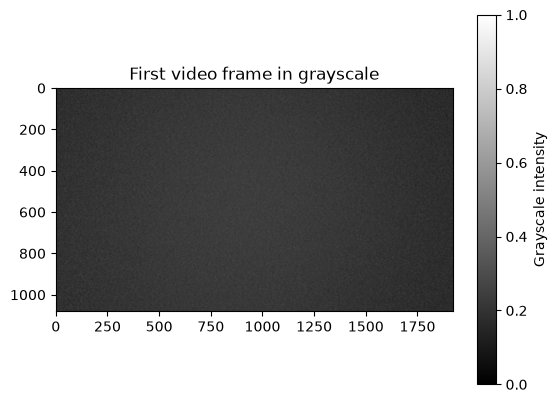

RGB frame shape: (1080, 1920, 3)
Grayscale frame shape: (1080, 1920)
Mean grayscale intensity: 0.21249159330708361


In [ ]:
# Read the first RGB frame from the video
frame = iio.imread(video_path, index=0, plugin="pyav")

# Convert the RGB frame to grayscale
gray = rgb2gray(frame)

# Display the grayscale frame
plt.imshow(gray, cmap="gray", vmin=0, vmax=1)
plt.title("First video frame in grayscale")
plt.colorbar(label="Grayscale intensity")
plt.show()

# Check the image dimensions and mean intensity
print("RGB frame shape:", frame.shape)
print("Grayscale frame shape:", gray.shape)
print("Mean grayscale intensity:", gray.mean())

In [ ]:
# Read the frame rate from the video metadata
metadata = iio.immeta(video_path, plugin="pyav")
fps = metadata["fps"]

# Convert each frame to grayscale and store its mean intensity
mean_gray = []

for frame in iio.imiter(video_path, plugin="pyav"):
    gray = rgb2gray(frame)
    mean_gray.append(gray.mean())

# Convert the results to a NumPy array
mean_gray = np.array(mean_gray)

# Approximate the sampling times using the nominal frame rate
time = np.arange(mean_gray.size) / fps

print("Frame rate (fps):", fps)
print("Number of frames:", mean_gray.size)
print("Last frame time (s):", time[-1])

Frame rate (fps): 29.97002997002997
Number of frames: 1852
Last frame time (s): 61.7617


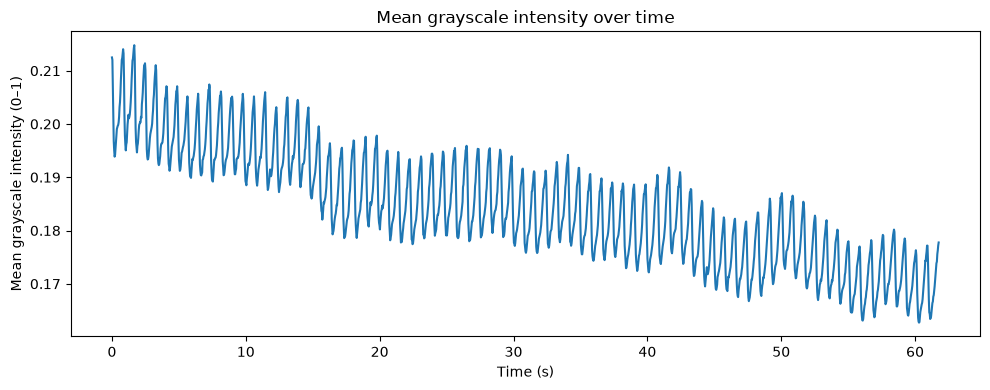

In [ ]:
# Plot mean grayscale intensity against time
plt.figure(figsize=(10, 4))
plt.plot(time, mean_gray)
plt.xlabel("Time (s)")
plt.ylabel("Mean grayscale intensity (0–1)")
plt.title("Mean grayscale intensity over time")
plt.tight_layout()
plt.show()